In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification

In [3]:
X, y = make_classification(
    n_samples=100, n_features=2,
    n_informative=1, n_redundant=0,
    n_classes=2, n_clusters_per_class=1,
    hypercube=False, random_state=41, class_sep=10
)

In [5]:
X.shape

(100, 2)

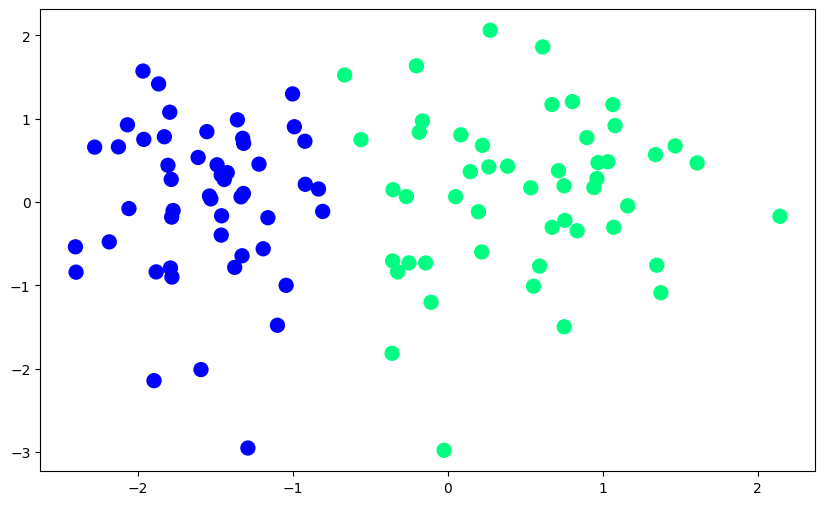

In [4]:
plt.figure(figsize=(10, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='winter', s=100)
plt.show()

## Step 1: Define the Perceptron and Step Functions
The perceptron function will update the weights based on misclassifications, and the step function will determine the output based on the sign of the input.

In [6]:
def step(z):
  return 1 if z>0 else 0

def perceptron(X, y):
    X = np.insert(X, 0, 1, axis=1)  # Add bias term to the input features
    weights = np.ones(X.shape[1])
    lr = 0.1  # Learning rate

    for i in range(1000):
        j = np.random.randint(0, 100)
        y_hat = step(np.dot(X[j], weights))
        weights = weights + lr * (y[j] - y_hat) * X[j]

    return weights[0], weights[1:]


## Step 2: Train our model

In [7]:
intercept_, coef_ = perceptron(X, y)
print("Weights:", coef_)
print("Intercept:", intercept_)

Weights: [1.47859929 0.06299028]
Intercept: 0.9


## Step 3: Plot the decision boundary

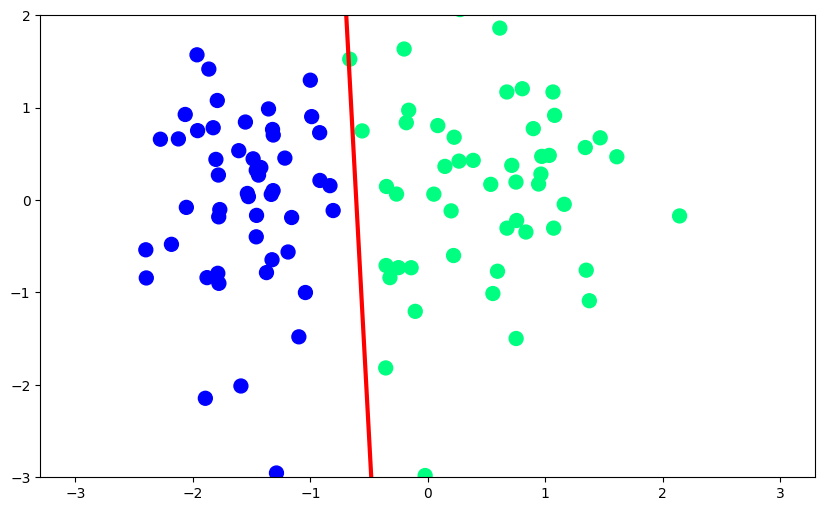

In [8]:
m = -(coef_[0] / coef_[1])
b = -(intercept_ / coef_[1])
x_input = np.linspace(-3, 3, 100)
y_input = m * x_input + b

plt.figure(figsize=(10, 6))
plt.plot(x_input, y_input, color='red', linewidth=3)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='winter', s=100)
plt.ylim(-3, 2)
plt.show()